In [1]:
# general imports
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
# mask-analog imports
import run_experiments as rexp
import plot_analogs as pa
import best_analogs as ba
# hide some warnings that are not helpful
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
# make plots show up in the notebook?
%matplotlib inline

# workflow for a new experiment

this is a simplified version of the tutorial that uses functions to bypass running every step

### 1. create a dictionary entry for the new experiment

In [2]:
# first, create an Experiments object which allows you to define a new experiment and run it
# the json file it is referencing saves all of your experiments in a file, so they can be run, re-run, referenced, etc.
exp_object = rexp.Experiments('experiments.json')
# print out the settings
print(exp_object.make_exp_dictionary.__doc__)
print('---------------------------------------------------------')
# these are all the available models and variables in the raw_data directory
# the number of members is also shown, along with the resolution
print(exp_object.list_variables)
print('---------------------------------------------------------')
# this lists all the regions available (you can add new regions to regions.json)
print(exp_object.list_regions)


        Make an experiment dictionary with the following settings:
            REQUIRED INPUTS
                - experiment_name: name of the experiment (how it will be saved and called)
                - variable_list: list of variable names to be included in the data
                - analog_models: which models to use for the analog split (run self.list_variables to see available options)
                - soi_models: which models to use for the training, and validation splits (run self.list_variables to see available options)
                - leadtime: time shift between inputs and target (should be a positive integer)
                - split: list with integer number of members to include in each split of the data (order should be: analog, training, validation)
                - region: the name (run self.list_regions to get available names) or list of boundary coordinates, i.e. [minlon, minlat, maxlon, maxlat] for the target region. To skip this processing step, pass False.
   

KeyError: 'ERA51940'

In [6]:
experiment_name = 'single_year1981'

In [7]:
# now, define a new experiment with all the settings you want to change
new_exp = exp_object.make_exp_dictionary(experiment_name, variable_list=['tas',], analog_models=["ERA51981"], soi_models=["ACCESS-ESM1-5", "CESM2", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], leadtime=1, output_period='1Y', region='western us', baseline=False, split=[1, 3, 2], method='jacob', prediction_nodes=[5, 5, 5], prediction_activation='elu', learning_rate=0.001, mask=False, data_period='monthly', roll_period=False, window=False, resolutions=[2.7672718509152787, 2.8125], season=False, time_range=None, norm_data=False, remove_trend=False, remove_seasonality=False, loss='mse', patience=50, min_delta=0.0005, batch_size=64, val_batch_size=2500, max_epochs=5000, mask_activation='relu', mask_init="ones", mask_l1=0.0, mask_l2=0.0, norm_weights=True, seed=20)

# this adds the experiment to the json file
exp_object.add_experiment(new_exp)

experiment_settings are:
{'single_year1981': {'experiment_name': 'single_year1981', 'variable_list': ['tas'], 'analog_models': ['ERA51981'], 'soi_models': ['ACCESS-ESM1-5', 'CESM2', 'GISS-E2-2-G', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0'], 'leadtime': 1, 'split': {'analog': 1, 'training': 3, 'validation': 2}, 'region': 'western us', 'prediction_nodes': [5, 5, 5], 'prediction_activation': 'elu', 'learning_rate': 0.001, 'method': 'jacob', 'mask': False, 'output_period': '1Y', 'data_period': 'monthly', 'roll_period': False, 'window': False, 'resolutions': [2.7672718509152787, 2.8125], 'season': False, 'time_range': None, 'norm_data': False, 'baseline': False, 'remove_trend': False, 'remove_seasonality': False, 'loss': 'mse', 'patience': 50, 'min_delta': 0.0005, 'batch_size': 64, 'val_batch_size': 2500, 'max_epochs': 5000, 'mask_activation': 'relu', 'mask_init': 'ones', 'mask_l1': 0.0, 'mask_l2': 0.0, 'norm_weights': True, 'seed': 20, 'avg_target': False, 'inputs_proc_steps': ["smooth_t

### 2. make the mask

In [8]:
# NOTE: this may need to be run in a terminal when the amount of data is large
exp_object.make_mask(experiment_name)

loading variables: tas
from models: ERA51981
successfully loaded 1 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/ERA51981/tas
#################################################################
processing analog input dataset
#################################################################
down-sampling dataset from 1M to 1Y
time period is now 1Y with 2 time steps
-------------------------------------------------------
syncing time period and dates between all variables and models
time period and dates synced, now using 2 dates
-------------------------------------------------------
regridding datasets to resolution [2.7672718509152787, 2.8125]
-------------------------------------------------------
shifting the data by -1 time steps
data shifted, now using 1 time steps
-------------------------------------------------------
-------------------------------------------------------
#################################################################
pro

<xarray.Dataset>
Dimensions:  (lat: 65, lon: 128)
Coordinates:
  * lat      (lat) float64 -88.62 -85.85 -83.08 -80.31 ... 82.95 85.72 88.49
  * lon      (lon) float64 0.0 2.812 5.625 8.438 ... 348.8 351.6 354.4 357.2
Data variables:
    tas      (lat, lon) float32 0.03323 0.03343 0.03363 ... 0.03166 0.03135

loading pre-saved analog dataset
loading pre-saved training dataset
loading pre-saved validation dataset
----------------------------------------------------------------
input and target datasets reshaped to (1, 65, 128, 1) and (1, 7, 5, 1)
input and target datasets reshaped to (2934, 65, 128, 1) and (2934, 7, 5, 1)
input and target datasets reshaped to (1956, 65, 128, 1) and (1956, 7, 5, 1)
----------------------------------------------------------------
loading pre-saved model
loading pre-saved mask


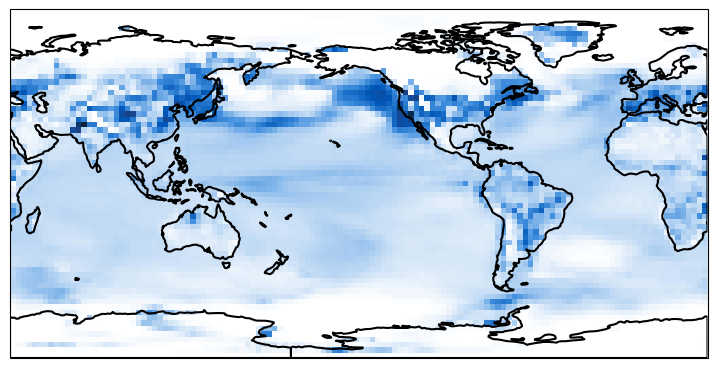

In [9]:
# plot the mask
exp_object.plot_mask(experiment_name, colorbar=False)
# exp_object.make_mask_gif(experiment_name)

### 3. generate a library of analogs and SOIs (states of interest)

now that the mask has been calculated, we can make regular analog forecasts using the mask

to do this, we need to generate a library of potential analogs that can be matched to our state of interest (the SOIs go in the same library)

In [10]:
# model_list is to set the models in the library, n_members sets how many (-1 uses all)
library = ba.BestAnalogs(experiment_name, model_list=["ACCESS-ESM1-5", "CESM2", "GISS-E2-2-G", "MIROC-ES2L", "MPI-ESM1-2-LR", "MRI-ESM2-0"], n_members=-1)
# if adding a model (or observations) with a different cadence, set the data_period -- this will add it to the library created in the line above
library = ba.BestAnalogs(experiment_name, model_list=["ERA5"], n_members=-1)

loading all available members, using 35 members from model: ACCESS-ESM1-5
loading variables: tas
from models: ACCESS-ESM1-5
successfully loaded 35 ensemble members from /Users/mafern/Desktop/mask-analog-projections/raw_data/monthly/ACCESS-ESM1-5/tas
#################################################################
processing ACCESS-ESM1-5 input dataset
#################################################################
down-sampling dataset from 1M to 1Y
time period is now 1Y with 251 time steps
-------------------------------------------------------
regridding datasets to resolution [2.7672718509152787, 2.8125]
-------------------------------------------------------
-------------------------------------------------------
#################################################################
processing ACCESS-ESM1-5 target dataset
#################################################################
down-sampling dataset from 1M to 1Y
time period is now 1Y with 251 time steps
--------------------

### 4. calculate the best analogs for a given SOI

In [13]:
# this ranks the analogs in the library for this SOI (in this case member 0 of BEST)
# this may also need to be run in the terminal
library.get_all_soi_analogs("ERA5", 0)

failed to load existing analogs
file path: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/single_year1981.pickle
saving to: /Users/mafern/Desktop/mask-analog-projections/saved_analogs/single_year1981.pickle


{'lat': array([-8.86163641e+01, -8.58490922e+01, -8.30818204e+01, -8.03145485e+01,
        -7.75472767e+01, -7.47800048e+01, -7.20127330e+01, -6.92454611e+01,
        -6.64781893e+01, -6.37109174e+01, -6.09436456e+01, -5.81763737e+01,
        -5.54091019e+01, -5.26418300e+01, -4.98745582e+01, -4.71072863e+01,
        -4.43400145e+01, -4.15727426e+01, -3.88054708e+01, -3.60381989e+01,
        -3.32709271e+01, -3.05036552e+01, -2.77363834e+01, -2.49691115e+01,
        -2.22018397e+01, -1.94345678e+01, -1.66672960e+01, -1.39000241e+01,
        -1.11327522e+01, -8.36548040e+00, -5.59820855e+00, -2.83093670e+00,
        -6.36648453e-02,  2.70360701e+00,  5.47087886e+00,  8.23815071e+00,
         1.10054226e+01,  1.37726944e+01,  1.65399663e+01,  1.93072381e+01,
         2.20745100e+01,  2.48417818e+01,  2.76090537e+01,  3.03763255e+01,
         3.31435974e+01,  3.59108692e+01,  3.86781411e+01,  4.14454129e+01,
         4.42126848e+01,  4.69799566e+01,  4.97472285e+01,  5.25145003e+01,
     

### 5. analysis and plots

once the above has been run, the library now contains inputs, targets, and indices (indices are added for each SOI)

previously saved best analogs for: ERA5


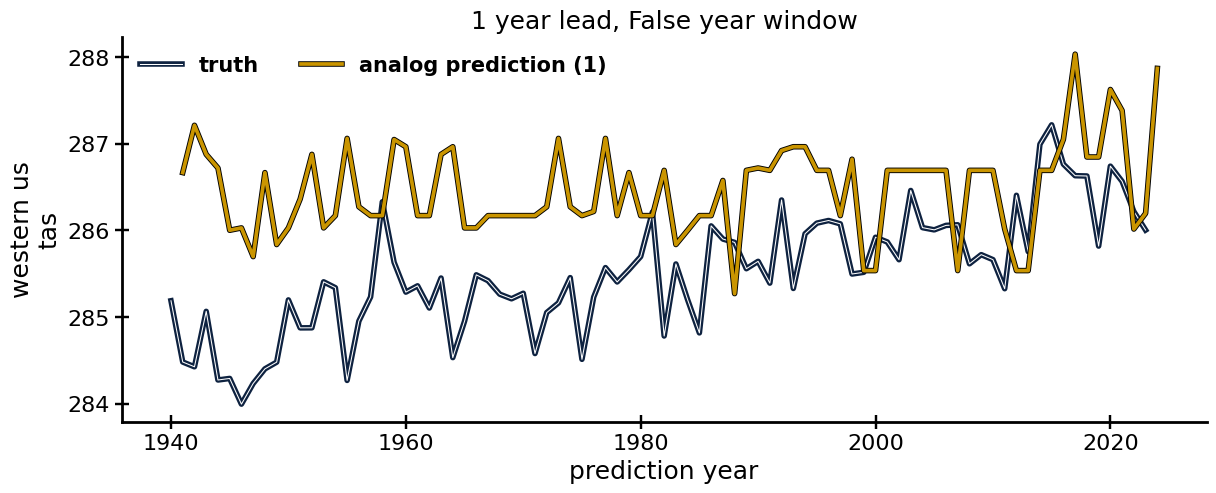

In [24]:
# load the library -- not passing any models means it will just load the previously processed data
library = pa.PlotAnalogs(experiment_name, "ERA5", 0, 'tas')
library.plot_prediction(1, savename=False)

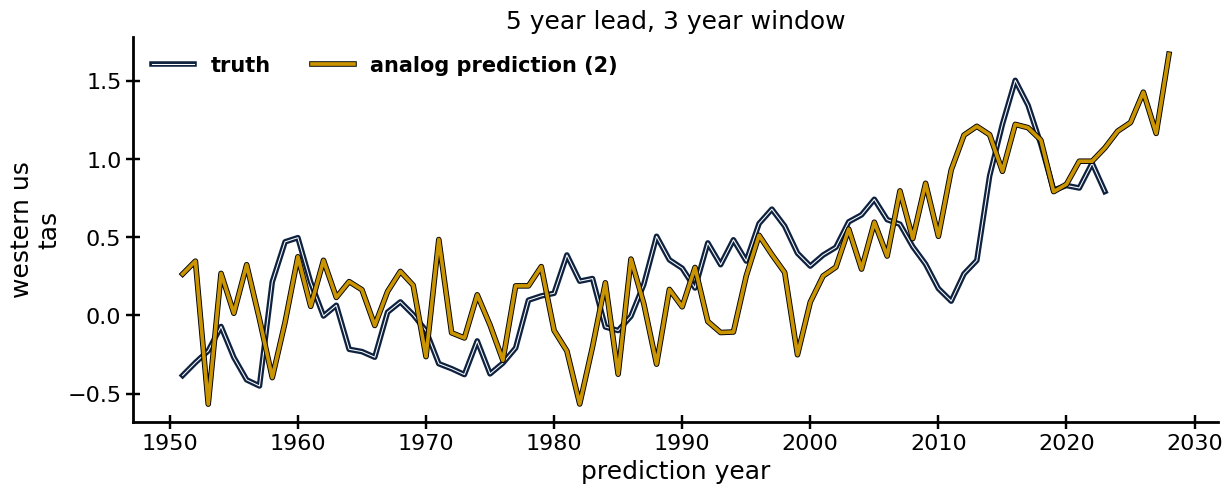

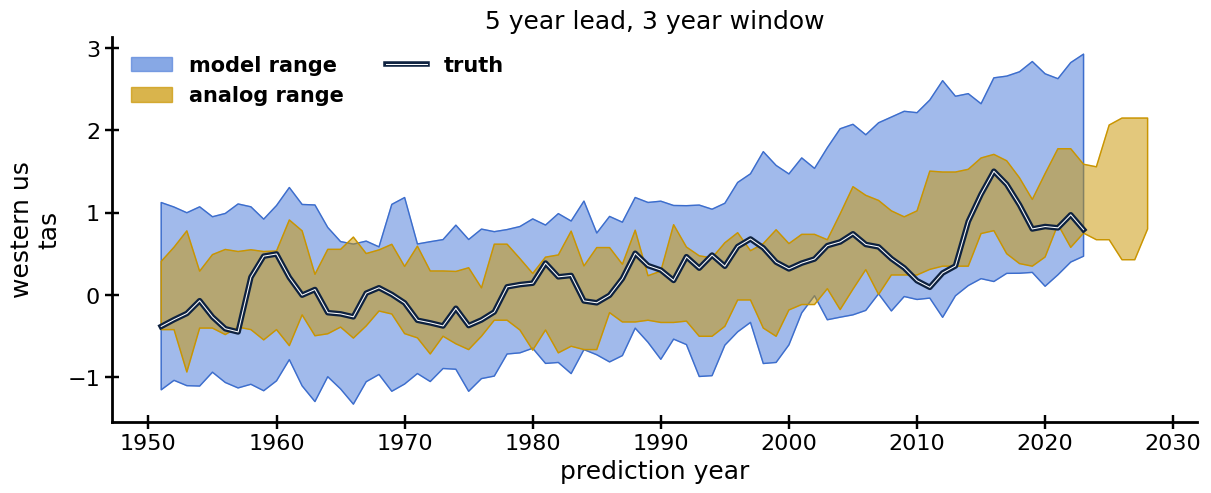

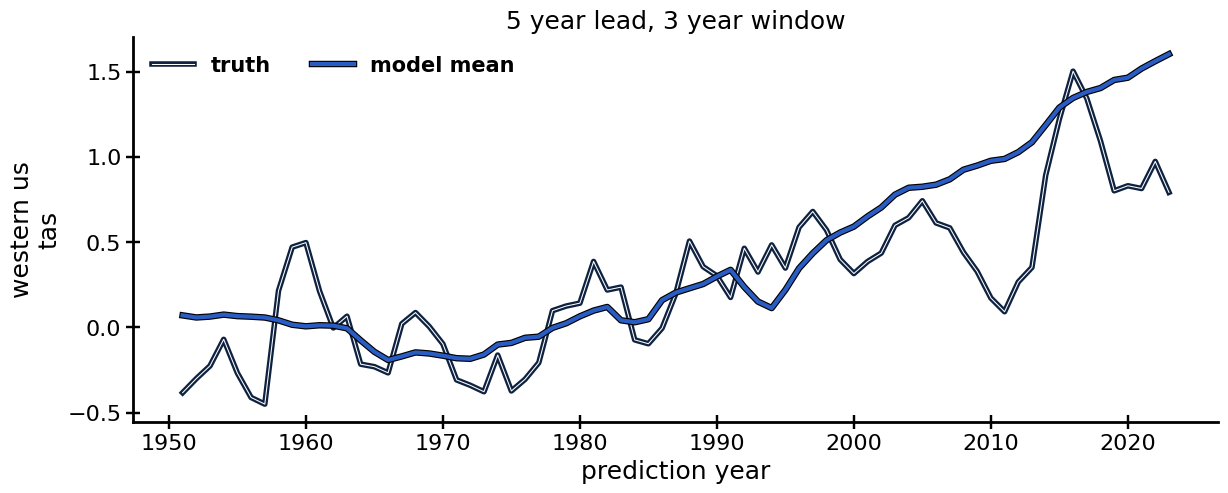

In [45]:
library.plot_prediction("BEST-YEARLY", 0, 'tas', 2)
library.plot_range("BEST-YEARLY", 0, 'tas', 10)
library.plot_model_mean("BEST-YEARLY", 0, 'tas')

/Users/mafern/Desktop/mask-analog-projections/plot_analogs.py:118: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  leg = ax[ii].legend(handles=handles, labels=labels, loc='upper left', ncols=2, frameon=False, prop={'size':'15', 'style':'oblique'})


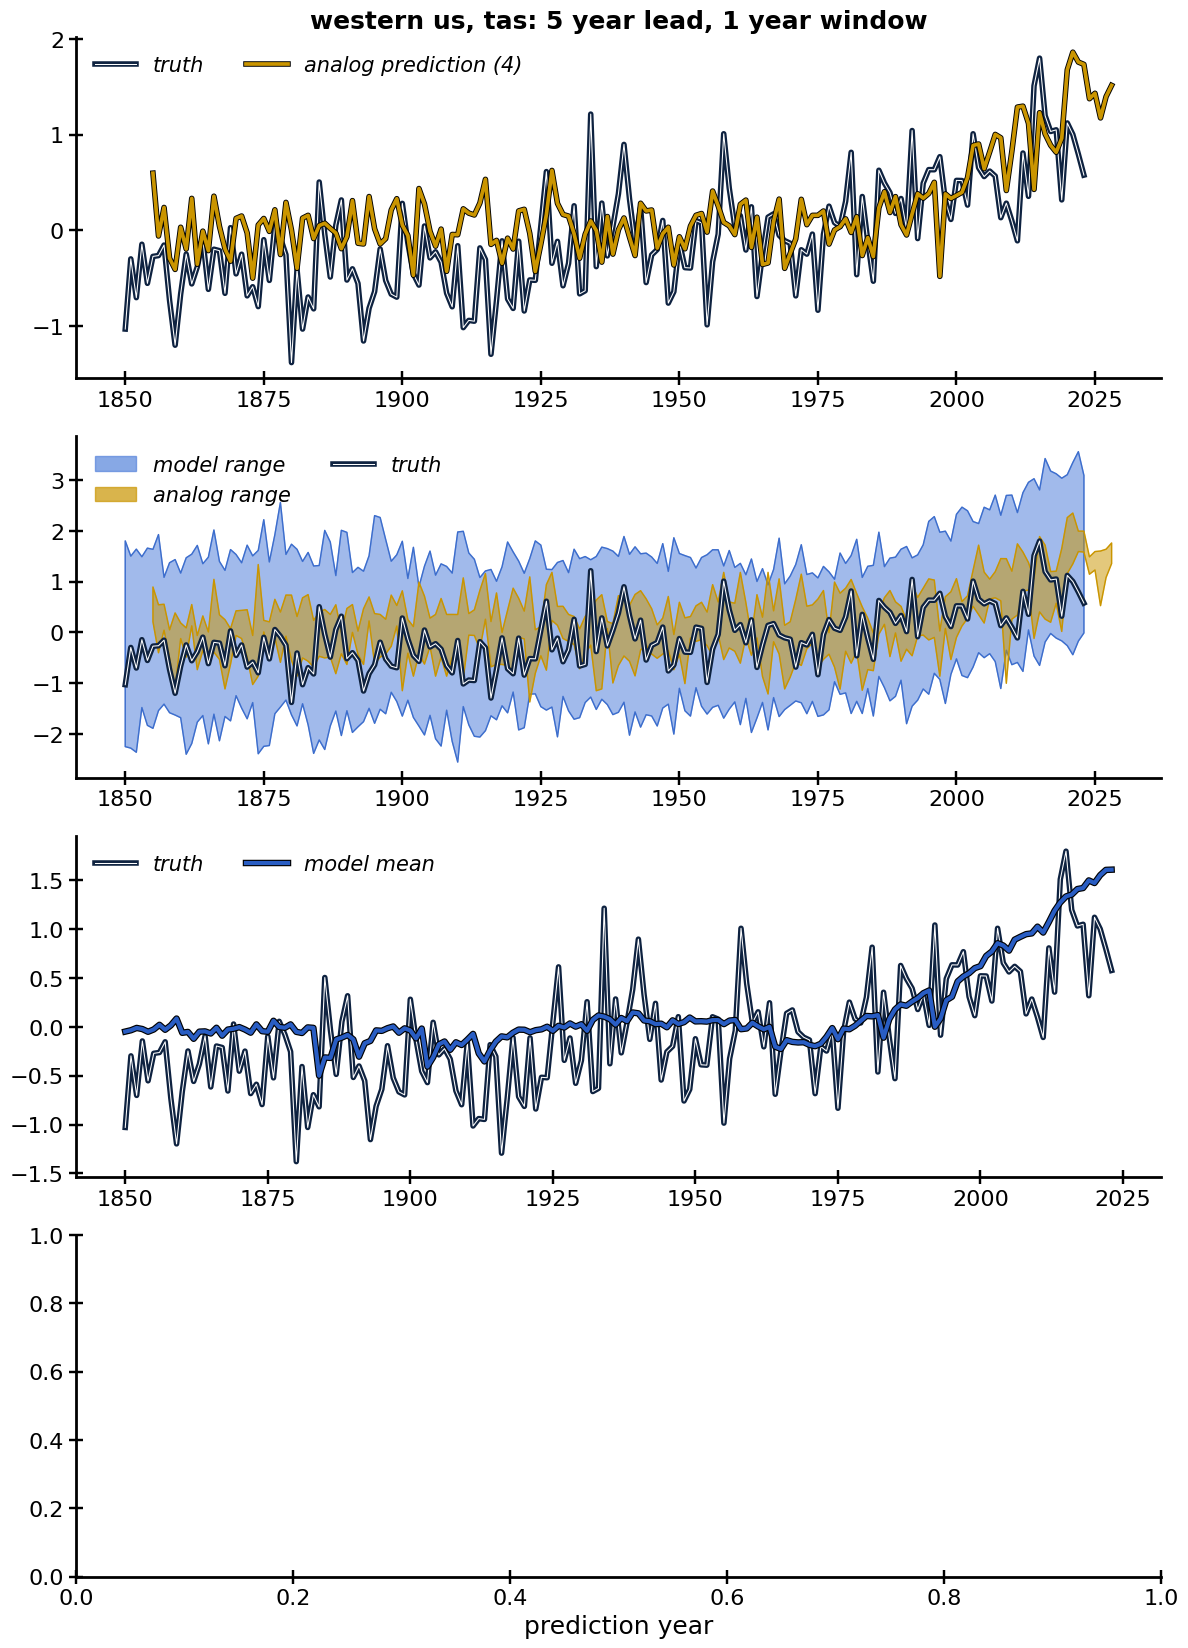

In [39]:
# suite of plots (which SOI to plot, which member, the variable, and number of analogs to show the mean of)
library.plot_prediction_suite("BEST-YEARLY", 0, 'tas', 4)

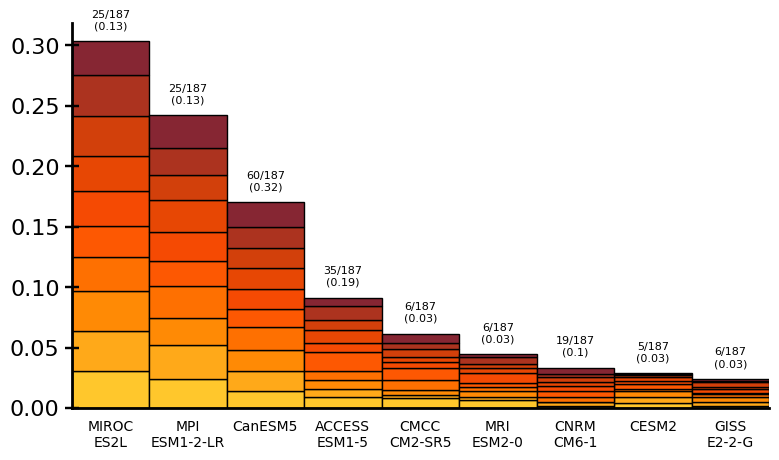

In [18]:
# here is the distribution of how often each model was picked as a top 10 analog
library.plot_model_distribution("BEST-YEARLY", 0, 'tas', 10)

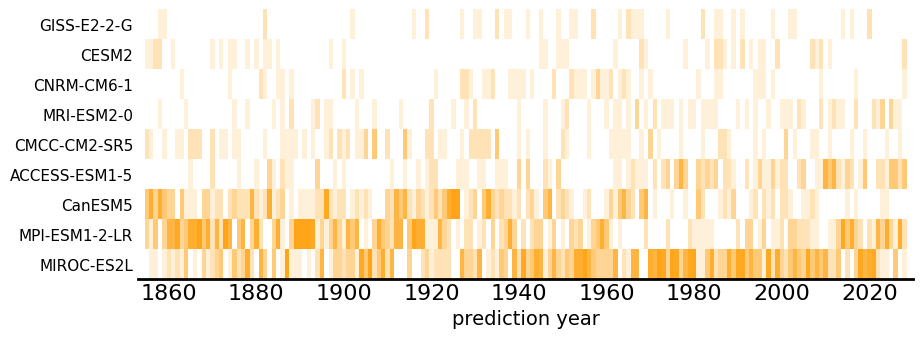

In [19]:
# or plot how often each model is picked as a function of time
library.plot_model_times("BEST-YEARLY", 0, 'tas', 10)

/opt/homebrew/Caskroom/miniforge/base/envs/new_analog/lib/python3.11/site-packages/xarray/core/duck_array_ops.py:188: RuntimeWarning: invalid value encountered in cast
  return data.astype(dtype, **kwargs)


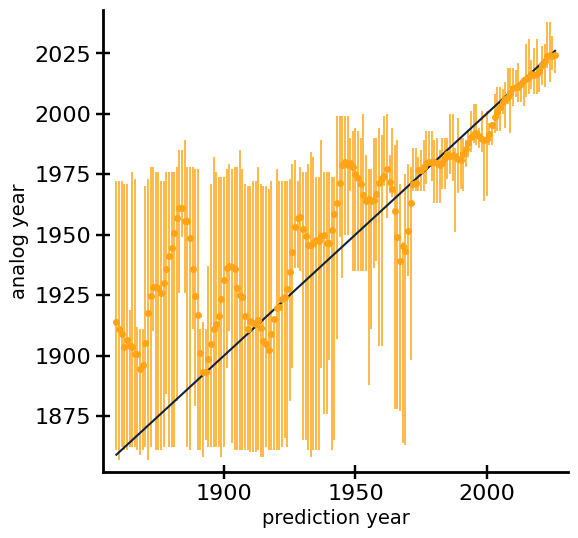

In [44]:
library.plot_selected_times("BEST-YEARLY", 0, 'tas', 10, 5)

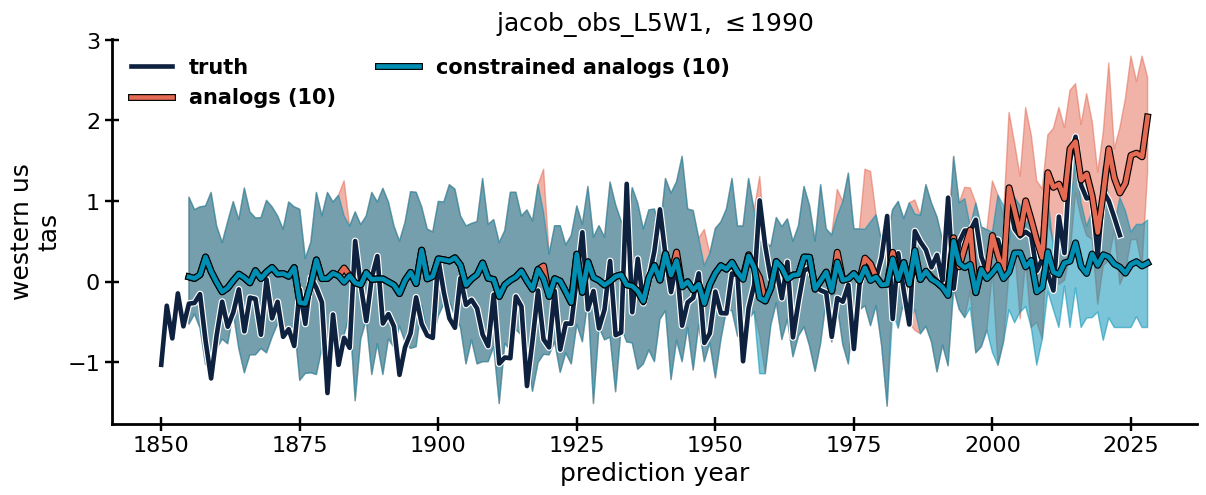

In [22]:
library.plot_constrained_prediction("BEST-YEARLY", 0, 'tas', 10, 1990)